# ДЗ Линейная регрессия

В данном задании мы рассмотрим набор данных об учащихся, собранный в 2006 году в одной из школ Португалии. Данные представлены в неудобном для машинного обучения виде, и содержат мусор. Ваша задача &mdash; привести их к надлежащему виду и обучить на них простую модель.

Данные состоят из четырех файлов:
- data.csv &mdash; основная таблица с информацией о учащихся
- scores.csv &mdash; список финальных оценок по одному из предметов (20-балльная шкала переведенная в проценты)
- attendance.csv &mdash; таблица посещений занятий по этому предмету
- school_support.txt &mdash; список учащихся, которым оказывается финансовая поддержка

Ваша задача &mdash; построить модель для предсказания финальных оценок исходя из всех остальных данных и проверить качество ее работы с помощью кросс-валидации. В качестве алгоритма мы будем использовать линейную регрессию

Расшифровка столбцов в data.csv для справки:
- age &mdash; возраст
- Medu &mdash; уровень образования матери (по некоторой условной шкале)
- Fedu &mdash; уровень образования отца (по некоторой условной шкале)
- traveltime &mdash; время в пути до школы (1 – < 15 мин., 2 – от 15 до 30 мин., 3 – от 30 мин. to 1 ч.
или 4 – > 1 ч.)
- studytime &mdash; время, затрачиваемое на занятия вне школы (1 – < 2 ч., 2 – от 2 до 5 ч., 3 – от 5 до 10 ч. или 4 – > 10 ч.)
- famrel &mdash; насколько хорошие отношения в семье у учащегося (по некоторой условной шкале)
- freetime &mdash; количество свободного времени вне школы (по некоторой условной шкале)
- goout &mdash; время, затрачиваемое на общение с друзьями (по некоторой условной шкале)
- Dalc &mdash; количество употребления алкоголя в учебные дни (по некоторой условной шкале)
- Walc &mdash; количество употребления алкоголя в неучебные дни (по некоторой условной шкале)
- health &mdash; уровень здоровья (по некоторой условной шкале)
- sex_M &mdash; пол: мужской (1) или женский (0)
- address_U &mdash; живет ли учащийся в городе (1) или в пригороде (0)
- famsize_LE3 &mdash; размер семьи: не больше 3 человек (1) или больше (0)
- Pstatus_T &mdash; живут ли родители вместе (1) или отдельно (0)
- nursery &mdash; посещал ли учащийся детский сад
- plans_university &mdash; планирует ли учащийся поступать в университет (-1 или 1)
- past_failures &mdash; количество неудовлетворительных оценок по другим предметам ранее (от 0 до 4)

*Примечание. Несколько признаков в данных содержат ошибки/проблемы/некорректности. Эти проблемы нужно исправить. Для
проверки &mdash; всего в данных таких проблем четыре.*

Начиная с 4 пункта делайте кроссвалидацию на 4 батча до и после, замеряйте результат

### Задача 1: сломанный признак (а может и не один)
__(1 балл)__

Загрузите таблицу data.csv.

Найдите в данных сломанный признак (он не соответствует описанию) и исправьте его.

In [1]:
# Your code here
# ...
import pandas as pd
import numpy as np

data = pd.read_csv("./data.csv")
scores = pd.read_csv("./scores.csv", header=None)
ds = data["plans_universitypast_failures"]
data = data.drop(columns=["plans_universitypast_failures"])

data["plans_university"] = np.where(ds < 0, -1, 1)

data["past_failures"] = abs(ds) % 10

### Задача 2: пропуски в данных 
__(1 балл)__

Проверьте, есть ли в данных пропуски (значения NaN). Замените все пропущенные значения на среднее значение этого признака по столбцу.

*Hint: изучите в pandas функции loc, isnull, а также передачу булевых массивов в качестве индексов.*

In [2]:
# Your code here
# ...
nan_cols = data.columns[data.isnull().any()]

for name in nan_cols:
    mean = data[name].mean()
    data.loc[data[name].isnull(), name] = mean

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               649 non-null    int64  
 1   Medu              649 non-null    int64  
 2   Fedu              649 non-null    int64  
 3   traveltime        649 non-null    int64  
 4   studytime         649 non-null    int64  
 5   famrel            649 non-null    int64  
 6   freetime          649 non-null    int64  
 7   goout             649 non-null    float64
 8   Dalc              649 non-null    float64
 9   Walc              649 non-null    float64
 10  health            649 non-null    int64  
 11  sex_M             649 non-null    int64  
 12  address_U         649 non-null    int64  
 13  famsize_LE3       649 non-null    int64  
 14  Pstatus_T         649 non-null    int64  
 15  nursery           649 non-null    int64  
 16  plans_university  649 non-null    int64  
 17  past_fai

### Задача 3: нормализация данных
__(1 балл)__

Нормализуйте данные любым способом, в современных библиотеках нормализация часто встроена внутрь модели, поэтому тут разницы может и не быть в качестве, но сделать надо

In [4]:
# Your code here
# ...x
data_norm = (data - data.mean()) / data.std()

pd.set_option('display.float_format', '{:.6f}'.format)
data_norm.describe()

,age,Medu,Fedu,traveltime,studytime,famrel,freetime,goout,Dalc,Walc,health,sex_M,address_U,famsize_LE3,Pstatus_T,nursery,plans_university,past_failures
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,0.000000,0.000000,0.000000,0.000000,-0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000,0.000000,-0.000000
std,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
min,-0.138027,-2.216415,-2.097064,-0.275135,-1.121943,-3.066455,-2.074296,-1.861294,-0.542273,-1.004971,-1.753634,-0.832735,-1.513566,-0.647676,-2.664872,-2.015947,-2.897041,-0.374017
25%,-0.134101,-0.453605,-1.187916,-0.275135,-1.121943,0.072550,-0.171514,-1.010117,-0.542273,-1.004971,-1.062195,-0.832735,-1.513566,-0.647676,0.374674,0.495281,0.344648,-0.374017
50%,-0.130176,-0.453605,-0.278768,-0.275135,0.083588,0.072550,-0.171514,-0.158939,-0.542273,-0.223597,0.320683,-0.832735,0.659674,-0.647676,0.374674,0.495281,0.344648,-0.374017
75%,-0.126251,1.309206,0.630380,0.093035,0.083588,1.118885,0.779877,0.692239,0.547389,0.557777,1.012122,1.199013,0.659674,1.541603,0.374674,0.495281,0.344648,-0.374017
max,7.618024,1.309206,1.539528,17.765188,2.494652,1.118885,1.731268,1.543416,3.816377,2.120525,1.012122,1.199013,0.659674,1.541603,0.374674,0.495281,0.344648,4.683000


### Задача 4: кросс-валидация для исходных данных
__(1 балл)__

Загрузите файл scores.csv и протестируйте, как линейная регрессия предсказывает ответ сейчас (с помощью кросс-валидации).

Кроссвалидацию сделайте по 4 разбивкам. Выведите качество в каждом их разбиений.

*Hint: воспользуйтесь sklearn.linear_model и sklearn.model_selection.*

In [5]:
# Your code here
# ...
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

model = LinearRegression()

scores_cv = cross_val_score(model, data_norm, scores, cv = 4, scoring="neg_mean_squared_error")

i = 1
for cv in scores_cv:
    print(f"{i} mse = {-cv}")
    i += 1
print(f"среднее значение mse = {-scores_cv.mean()}")

1 mse = 170.8862153241681
2 mse = 243.35155620082972
3 mse = 242.82471577762547
4 mse = 229.76361866794772
среднее значение mse = 221.70652649264275


### Задача 5: полные данные
__(2 балла)__

Воспользуйтесь файлами attendance.csv и school_support.txt для того, чтобы добавить новые признаки в данные. Желательно по максимуму использовать возможности pandas для упрощения преобразований.

school_suport число в строке значит что i-ый школьник из исходной таблицы получал мат помощь (обратите внимание что строк в файле меньше, подумайте как правильно импортировать данные)

Добавьте данные таким образом, чтобы качество выросло

In [6]:
# Your code here
# ...
attendance = pd.read_csv("./attendance.csv", sep=";")
attendance.head()
cnt = (attendance == '+').sum(axis=1)

support = pd.read_csv("./school_support.txt", header=None)

data["support"] = np.where(data.index.isin(support[0]), 1, 0)
data["attendance"] = cnt;
data["unattendance"] = 32 - cnt

In [7]:
model = LinearRegression()

data_norm = (data - data.mean()) / data.std()

scores_cv = cross_val_score(model, data_norm, scores, cv = 4, scoring="neg_mean_squared_error")

i = 1
for cv in scores_cv:
    print(f"{i} mse = {-cv}")
    i += 1
print(f"среднее значение mse = {-scores_cv.mean()}")

1 mse = 164.03472760040611
2 mse = 237.18988857731242
3 mse = 252.1033348467021
4 mse = 229.55870300415052
среднее значение mse = 220.72166350714278


### Задача 6: борьба с выбросами
__(1.5 балла)__

Качество предсказания может ухудшаться, если в данных присутствуют корректные значения признаков (с точки зрения чтения данных и применения методов), но не соответствующие реальным объектам. Например, данные могли быть введены в неверном формате, а потом слишком грубо приведены к общему виду, из-за чего ошибка не была замечена.
Попробуем от такого избавиться &mdash; а для этого такие объекты нужно сначала найти. Конечно, нам еще недоступны многие продвинутые способы, но давайте попробуем обойтись простыми.

Первый способ это сделать &mdash; посмотреть для каждого признака на распределение его значений и проверить крайние значения на правдоподобность. (постройте гистограммы для признаков, как минимум для подозрительных)

*Hint 1: используйте функцию DataFrame.hist*

*Hint 2: в описании датасета выше есть информация, необходимая для восстановления правильных значений*

In [8]:
# Your code here
# ...
data.describe()

,age,Medu,Fedu,traveltime,studytime,famrel,freetime,goout,Dalc,Walc,...,sex_M,address_U,famsize_LE3,Pstatus_T,nursery,plans_university,past_failures,support,attendance,unattendance
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,...,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,50.164869,2.514638,2.306626,1.747304,1.930663,3.930663,3.180277,3.186728,1.497653,2.286159,...,0.409861,0.696456,0.295840,0.876733,0.802773,0.787365,0.221880,0.104777,28.340524,3.659476
std,254.768848,1.134552,1.099931,2.716138,0.829510,0.955717,1.051093,1.174843,0.917715,1.279797,...,0.492187,0.460143,0.456771,0.328996,0.398212,0.616962,0.593235,0.306502,4.640759,4.640759
min,15.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,4.000000,3.000000,2.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,26.000000,0.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,4.000000,3.000000,3.000000,1.000000,2.000000,...,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,30.000000,2.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,5.000000,4.000000,4.000000,2.000000,3.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,32.000000,6.000000
max,1991.000000,4.000000,4.000000,50.000000,4.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,32.000000,32.000000


In [9]:
# Your code here
# ...
# возраст укаазан в годах, время указано в пути до школы не переведены в шкалу, 
mask = data["age"] >= 1000
data.loc[mask, "age"] = 2006 - data.loc[mask, "age"]

data.loc[(data["traveltime"] > 4) & (data["traveltime"] <= 15), "traveltime"] = 1
data.loc[(data["traveltime"] > 15) & (data["traveltime"] <= 30), "traveltime"] = 2
data.loc[(data["traveltime"] > 30) & (data["traveltime"] <= 60), "traveltime"] = 3
data.loc[(data["traveltime"] > 60), "traveltime"] = 4

In [10]:
data.describe()

,age,Medu,Fedu,traveltime,studytime,famrel,freetime,goout,Dalc,Walc,...,sex_M,address_U,famsize_LE3,Pstatus_T,nursery,plans_university,past_failures,support,attendance,unattendance
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,...,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,3.930663,3.180277,3.186728,1.497653,2.286159,...,0.409861,0.696456,0.295840,0.876733,0.802773,0.787365,0.221880,0.104777,28.340524,3.659476
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.955717,1.051093,1.174843,0.917715,1.279797,...,0.492187,0.460143,0.456771,0.328996,0.398212,0.616962,0.593235,0.306502,4.640759,4.640759
min,15.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,4.000000,3.000000,2.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,26.000000,0.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,4.000000,3.000000,3.000000,1.000000,2.000000,...,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,30.000000,2.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,5.000000,4.000000,4.000000,2.000000,3.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,32.000000,6.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,32.000000,32.000000


__(1.5 балла)__

Другой простой способ найти выбросы &mdash; сделать предсказание и посчитать ошибку на каждом объекте по отдельности и посмотреть на объекты с наибольшей ошибкой. Обучите линейную регрессию (функция fit) и для каждого объекта посчитайте среднеквадратичное отклонение. Постройте гистограмму распределения ошибок. Посмотрите на гистограмму и удалите из выборки те объекты на которых ошибка слишком большая.

Обратите внимание, что просто удалять все объекты с высокой ошибкой нельзя &mdash; это, конечно, хороший способ добиться меньшей ошибки (на данной выборке), но одновременно вы ухудшите обобщающую способность алгоритма. Вместо этого вам нужно найти однозначно ошибочные записи и их исправить.

*Hint: возможно, все проблемы уже были найдены первым способом; для проверки &mdash; в сумме здесь нужно исправить 3 проблемы.*

Для поиска ошибки на одном отдельном обьекте придётся обучить линейную регрессию руками. Частичный пример, допишите код. Постройте гистограмму распределения ошибок

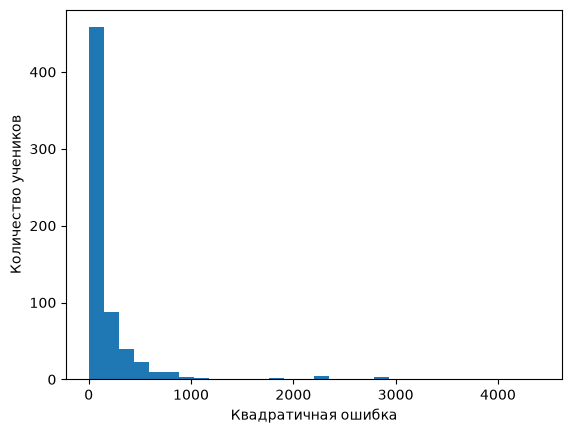

In [11]:
# Your code here
# ...
import matplotlib.pyplot as plt

model = LinearRegression()

data_norm = (data - data.mean()) / data.std()

model.fit(data_norm, scores)

pred = model.predict(data_norm)

errors = (scores.values.ravel() - pred.ravel()) ** 2

plt.hist(errors, bins=30)
plt.xlabel("Квадратичная ошибка")
plt.ylabel("Количество учеников")
plt.show()

In [12]:
# Your code here
# ...
ind = np.argsort(errors)[-15:]
indData = data.index[ind]

data.loc[indData]

,age,Medu,Fedu,traveltime,studytime,famrel,freetime,goout,Dalc,Walc,...,sex_M,address_U,famsize_LE3,Pstatus_T,nursery,plans_university,past_failures,support,attendance,unattendance
137,19,1,1,2,1,5,5,5.000000,2.000000,3.000000,...,0,1,0,1,1,-1,1,0,32,0
501,19,1,1,2,1,4,3,2.000000,1.000000,3.000000,...,1,0,0,1,1,1,1,0,32,0
231,16,2,2,1,2,3,1,2.000000,1.000000,1.000000,...,0,1,0,1,1,1,1,1,20,12
492,18,4,2,2,1,5,4,3.000000,4.000000,3.000000,...,1,0,0,1,1,1,1,0,32,0
557,17,2,2,1,1,1,2,1.000000,2.000000,3.000000,...,1,1,0,1,1,1,1,0,32,0
423,16,1,1,2,2,5,4,5.000000,4.000000,5.000000,...,1,1,0,1,1,1,0,0,32,0
404,17,4,3,2,2,4,5,5.000000,1.000000,3.000000,...,1,0,0,1,0,1,1,0,28,4
462,18,2,2,3,2,4,3,3.000000,1.000000,1.000000,...,0,0,0,1,1,1,1,0,32,0
257,15,3,2,1,2,3,3,2.000000,1.000000,1.000000,...,0,1,0,1,1,1,1,0,30,2
303,18,2,1,2,1,4,4,3.000000,1.000000,3.000000,...,1,0,0,1,0,1,0,0,32,0


In [13]:
data = data.drop(indData)
scores = scores.drop(indData)

### Финальное предсказание и отчёт (1 балл)

Проведите предсказание еще раз и сравните качество с исходным. Запишите свои наблюдения - как изменялось качество обучения модели при использовании разных модификаций данных. 

In [14]:
# Your code here
# ...
model = LinearRegression()

data_norm = (data - data.mean()) / data.std()

scores_cv = cross_val_score(model, data_norm, scores, cv = 4, scoring="neg_mean_squared_error")

i = 1
for cv in scores_cv:
    print(f"{i} mse = {-cv}")
    i += 1
print(f"среднее значение mse = {-scores_cv.mean()}")

1 mse = 145.38863445015062
2 mse = 162.71623063780308
3 mse = 133.1047798689393
4 mse = 132.5005487871888
среднее значение mse = 143.42754843602046


### Отчет

Изначальное среднее MSE состовляло примерно 221,7. При добавлении трех факторов "support", "attendance", "unattendance" 
из входных файлов, среднее MSE улучшилось до 220,7. Выбросы сильно влияли на итоговую ошибку. При удалении выбросов среднее MSE упало до 143.